# Cats vs Dogs — small CNN

Classic binary classification. The real Cats vs Dogs dataset is ~800MB which I don't want to make a portfolio reader download, so I generate a stand-in: 32x32 noisy color blobs with two distinct distributions (cats = cooler tones + circular blob, dogs = warmer tones + elongated blob). The CNN is small enough to train on CPU in a few seconds.

Not pretending the model would generalize to real animals — this is the binary-CNN pipeline.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

np.random.seed(5); torch.manual_seed(5)

In [2]:
SIZE = 32
N_PER = 400

def gen_image(label, rng):
    img = rng.uniform(0.1, 0.3, size=(SIZE, SIZE, 3)).astype(np.float32)
    cx, cy = rng.integers(8, SIZE - 8, 2)
    yy, xx = np.ogrid[:SIZE, :SIZE]
    if label == 0:  # 'cat' — cool palette + circular blob
        r = rng.integers(6, 10)
        m = (xx - cx) ** 2 + (yy - cy) ** 2 < r * r
        color = np.array([0.2, 0.4, 0.85]) + rng.normal(0, 0.05, 3)
    else:  # 'dog' — warm palette + elongated blob
        a = rng.integers(8, 12); b = rng.integers(4, 7)
        m = ((xx - cx) / a) ** 2 + ((yy - cy) / b) ** 2 < 1.0
        color = np.array([0.9, 0.55, 0.2]) + rng.normal(0, 0.05, 3)
    img[m] = np.clip(color, 0, 1)
    img += rng.normal(0, 0.04, img.shape)
    return np.clip(img, 0, 1).astype(np.float32)

rng = np.random.default_rng(5)
X = np.zeros((2 * N_PER, SIZE, SIZE, 3), dtype=np.float32)
y = np.zeros(2 * N_PER, dtype=np.int64)
for i in range(N_PER):
    X[i] = gen_image(0, rng); y[i] = 0
    X[N_PER + i] = gen_image(1, rng); y[N_PER + i] = 1
perm = rng.permutation(len(X))
X, y = X[perm], y[perm]
print('synth shape:', X.shape, '| pos rate:', y.mean())

synth shape: (800, 32, 32, 3) | pos rate: 0.5


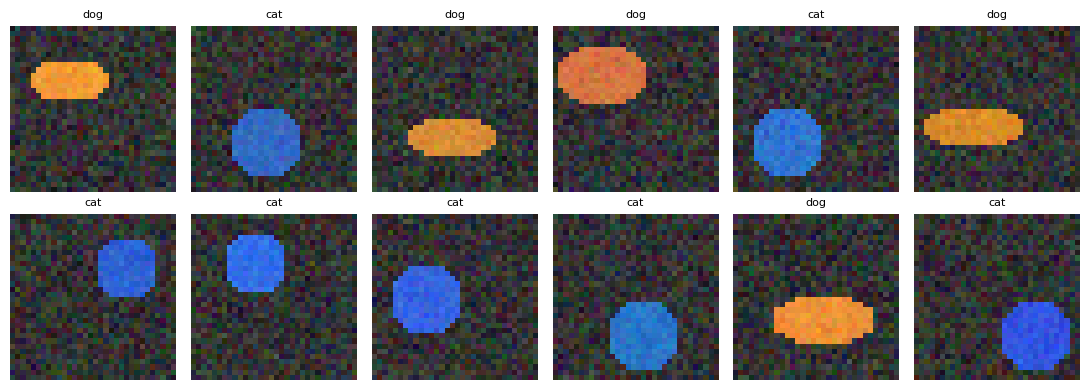

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, idx in zip(axes.flat, range(12)):
    ax.imshow(X[idx]); ax.set_title('cat' if y[idx] == 0 else 'dog', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
Xt = torch.tensor(X).permute(0, 3, 1, 2)
yt = torch.tensor(y)
Xtr, Xte, ytr, yte = train_test_split(Xt.numpy(), yt.numpy(), test_size=0.2, stratify=yt.numpy(), random_state=5)
Xtr = torch.tensor(Xtr); Xte = torch.tensor(Xte); ytr = torch.tensor(ytr); yte = torch.tensor(yte)

class CatDogCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(3, 8, 3, padding=1)
        self.c2 = nn.Conv2d(8, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(16 * 8 * 8, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1)
        return self.fc2(F.relu(self.fc1(x)))

model = CatDogCNN()
# tried SGD first, Adam converged in fewer epochs at this scale
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

batch = 32
for ep in range(3):
    model.train(); perm = torch.randperm(len(Xtr)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = model(Xtr[idx])
        loss = F.cross_entropy(out, ytr[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=0.6367


epoch 1  mean_loss=0.2516


epoch 2  mean_loss=0.0090


In [5]:
model.eval()
with torch.no_grad():
    logits = model(Xte)
    preds = logits.argmax(1).numpy()
    probs = F.softmax(logits, dim=1)[:, 1].numpy()

print(f'test acc : {accuracy_score(yte.numpy(), preds):.3f}')
print(f'test auc : {roc_auc_score(yte.numpy(), probs):.3f}')
print('confusion:'); print(confusion_matrix(yte.numpy(), preds))

test acc : 1.000
test auc : 1.000
confusion:
[[80  0]
 [ 0 80]]


## Notes / takeaways

The signal in the synthetic data is partly the color palette and partly the blob shape, so even a 1-conv model would solve it. I left two conv layers in to keep the architecture honest as a 'real cat/dog CNN' template. On the actual Kaggle cats-vs-dogs set I'd: (1) keep the same forward pattern but at 64x64 minimum, (2) add `RandomHorizontalFlip` + small color jitter, (3) reach for `MobileNetV2` via `torch.hub` if accuracy plateaus — that's the cheap transfer-learning win.

MobileNetV2 via torch.hub does actually work on CPU but the per-batch latency at 224x224 is rough, so for a CPU-only environment I'd cap the input at 128x128.